# Ice Stun (Harakim)

Ice Stun replaces Stun once the talent is learned (the `SK_STUN` investment moves to
`SK_ICE_STUN`). The stun is identical to Stun's. Every target it freezes also gets an ice marker,
and if that target dies while the marker is up, 75% of the time it shatters and deals true damage
to every character on the eight surrounding tiles.

| | |
|---|---|
| Class | Harakim |
| Target | Primary target + adjacent characters attacking the caster (cross pattern, as Stun) |
| Cost | 20 mana, spent before the roll |
| Cooldown | 3 s exhaust |
| Landing roll | primary: `chance_base(skill, 12, effective_resist(Resist))`; adjacent: `p + rand(20) > R_eff + rand(20)` |
| Stun | `spell_stun`: $p' + 36$ ticks with $p' = \text{race}(\text{immunity}(p))$ |
| Marker | temp `SK_ICE_STUN`, power $b = p$ (×1.2 after an element switch), lasts $b + 36$ ticks |
| Burst | on death with the marker up: 75% chance of `a_hp -= max(1, ⌊3b/2⌋)` HP on each of the 8 neighbours (no armor, no roll; skips the caster, bodies and anything `may_aoe_attack` rejects) |
| Source | `server/src/driver/skill/harakim.rs::skill_ice_stun`, `attach_ice_stun_marker`; `server/src/state/death.rs::trigger_ice_stun_burst_on_death`; `driver/skill/stun.rs::spell_stun` |

---

# Formula

With $p$ the raw modified skill and $b$ the burst power ($b = p$, or $\lfloor 1.2p \rfloor$ when
the cast switched elements):

$$
\text{stun} = \frac{p' + 36}{36}\ \text{s}
\qquad
\text{marker window} = \frac{b + 36}{36}\ \text{s}
\qquad
\text{burst} = \max\!\left(1,\ \left\lfloor \tfrac{3b}{2} \right\rfloor\right)\ \text{HP per neighbour}
$$

$$
E[\text{burst HP}] = 0.75 \cdot n \cdot \text{burst}
\qquad (n \le 8 \text{ occupied neighbours})
$$

The marker stores the raw skill, so the target's Immunity shortens the stun but not the burst.
A neighbour killed by the burst runs its own death hooks, so a marked neighbour can burst in turn.

| Quantity | Breakpoint |
|---|---|
| Burst at the raise caps | 157 HP at 105 (189 with Element Switching), 180 at 120 |
| Marker window | 3.9 s at 105, 4.3 s at 120 |
| Ceiling | none: burst and duration grow linearly |

---

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import mag_model as mm

mm.apply_style()
P = mm.SKILL_RANGE
BURST_CHANCE = 0.75
NEIGHBOURS = 8
ELEMENT_SWITCH_PCT = 20

# Model

In [2]:
def stun_s(p, immun=0):
    return (mm.spell_power(p, immun, "Harakim") + mm.TICKS) / mm.TICKS


def marker_s(p, switched=False):
    return (burst_power(p, switched) + mm.TICKS) / mm.TICKS


def burst_power(p, switched=False):
    p = np.asarray(p)
    return p * (100 + ELEMENT_SWITCH_PCT) // 100 if switched else p


def burst_hp(p, switched=False):
    return np.maximum(1, mm.idiv(burst_power(p, switched) * 3, 2))


def expected_burst(p, n=NEIGHBOURS, switched=False):
    """Expected HP the burst deals across `n` occupied neighbouring tiles."""
    return BURST_CHANCE * n * burst_hp(p, switched)


def p_land(p, resist, adjacent=False):
    if adjacent:
        return mm.p_opposed_d20(p, resist)
    return mm.p_chance_base(p, 12, resist)

# Validation

- `ice_stun_marker_records_caster_and_power`: power 40 is stored unchanged with the caster in
  `data[0]`, and the marker is active (duration $40 + 36$ ticks).
- `learn_harakim_ice_stun_replaces_stun_with_existing_investment`: learning the talent moves the
  Stun investment to Ice Stun.
- `element_switching_boosts_changed_element_damage`: 100 → 120 after a switch.

In [3]:
assert burst_power(40) == 40 and marker_s(40) * mm.TICKS == 76
assert burst_power(100, switched=True) == 120
assert burst_hp(0) == 1 and burst_hp(1) == 1 and burst_hp(105) == 157 and burst_hp(120) == 180
assert burst_hp(105, switched=True) == 189
assert stun_s(105) * mm.TICKS == 141 and stun_s(105, immun=50) * mm.TICKS == 116
print("Ice Stun model OK")

Ice Stun model OK


# Plots

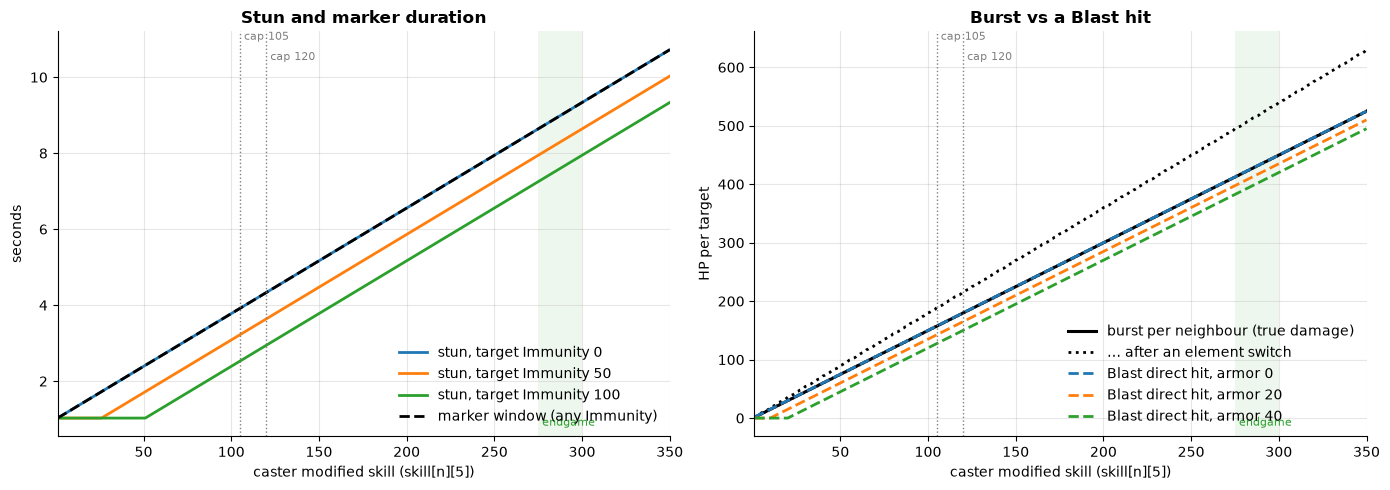

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
for imm in (0, 50, 100):
    ax.plot(P, stun_s(P, imm), label=f"stun, target Immunity {imm}")
ax.plot(P, marker_s(P), color="black", ls="--", label="marker window (any Immunity)")
mm.skill_axis(ax, "seconds", "Stun and marker duration")
mm.mark_caps(ax)
ax.legend()

ax = axes[1]
ax.plot(P, burst_hp(P), color="black", lw=2.2, label="burst per neighbour (true damage)")
ax.plot(P, burst_hp(P, switched=True), color="black", ls=":", label="… after an element switch")
for armor in (0, 20, 40):
    ax.plot(P, mm.hurt_hp(2 * mm.spell_power(P, 0, "Harakim"), armor, kind=1), ls="--",
            label=f"Blast direct hit, armor {armor}")
mm.skill_axis(ax, "HP per target", "Burst vs a Blast hit")
mm.mark_caps(ax)
ax.legend()
plt.tight_layout()

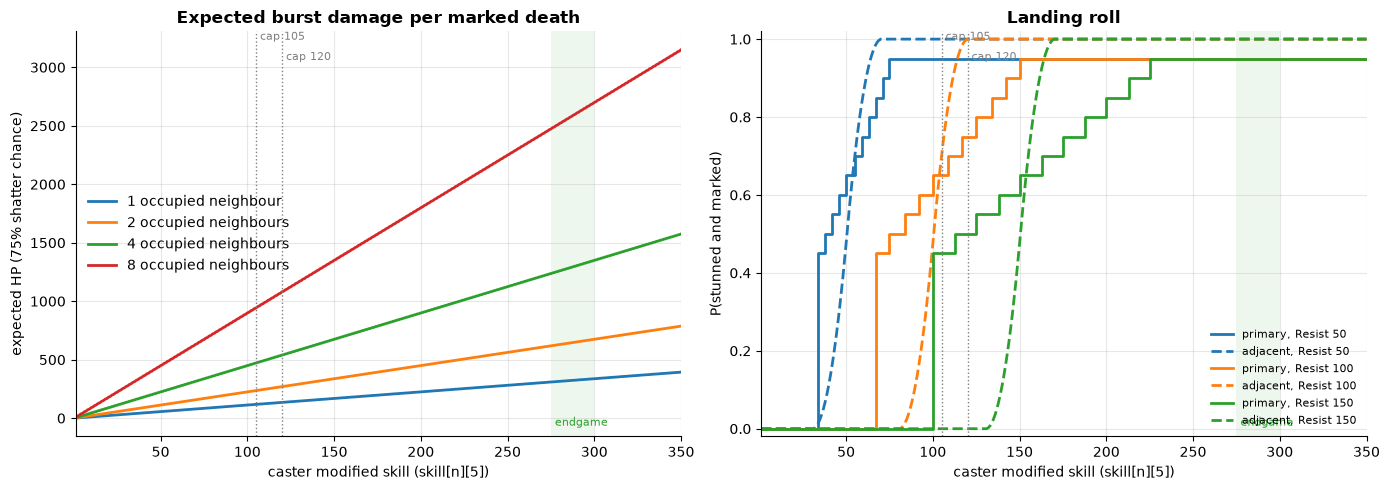

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
for n in (1, 2, 4, 8):
    ax.plot(P, expected_burst(P, n), label=f"{n} occupied neighbour{'s' if n > 1 else ''}")
mm.skill_axis(ax, "expected HP (75% shatter chance)", "Expected burst damage per marked death")
mm.mark_caps(ax)
ax.legend()

ax = axes[1]
for r in (50, 100, 150):
    line, = ax.step(P, p_land(P, r), where="post", label=f"primary, Resist {r}")
    ax.plot(P, p_land(P, r, adjacent=True), color=line.get_color(), ls="--", label=f"adjacent, Resist {r}")
mm.skill_axis(ax, "P(stunned and marked)", "Landing roll")
ax.set_ylim(-0.02, 1.02)
mm.mark_caps(ax)
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()

# Observations

- Cost, roll and duration match Stun (3.9 s at skill 105
  against Immunity 0). The talent is a pure upgrade: nothing is traded away.
- At skill 105 a shatter deals 157 HP
  to every neighbour. That equals a Blast direct hit against armor 0, and beats it by 0.75 HP per
  armor point otherwise. It costs no mana, has no resist roll and no Immunity reduction. With
  Element Switching it is 189 HP. In a crowd of eight that is 940 HP expected per marked death.
- The marker lasts $b + 36$ ticks (3.9 s at 105), the
  same as the stun against Immunity 0. The target must die inside that window, so the burst rewards
  stunning something that is already low or focus-fired. Immunity shortens the stun but not the
  marker, so a high-Immunity target can recover and still shatter if it dies in time.
- A neighbour killed by the burst runs `do_character_killed`, which fires
  its own marker. Ice Stun also marks the attackers adjacent to the caster, and those stand next to
  each other, so one kill can set off two or three shatters in a tight pack.
- Drop the burst to $p$ (105 HP at 105) or apply armor through
  `do_hurt(…, 1)`, and stop the chain by skipping neighbours that carry a marker of their own.